# CAO-DF — Phase 10: Statistical Analysis

**Project:** CAO-DF: A Cost-Aware Decision Framework for Adaptive Optimization of Apache Spark Data Pipelines
**Author:** Mustaqeem Shaikh

This notebook is the full statistical analysis of every measured run (A1 partition tuning,
A2 file compaction and the E6 validation on unseen workloads). It answers three questions:

1. **Is the data sound?** (schema, counts, noise)
2. **How big are the effects, and how sure are we?** (medians, bootstrap 95% confidence intervals, effect sizes)
3. **Do the hypotheses hold?** H1 — the benefit of an optimization depends on the workload; H2 — the cost-aware
   framework spends less than always running the static default.

**How to read the statistics.** Every cell has only 5 repeated runs (3 for validation). With so few runs a
p-value can never be very small — the exact Wilcoxon test cannot go below p = 0.0625 for 5 pairs even when
every run improves. So the evidence is carried by **effect sizes and bootstrap confidence intervals**, as
planned in the master document (§22). P-values are reported for completeness only.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Data checks |
| 3 | Descriptive statistics and run-to-run noise |
| 4 | A1 — shuffle-partition tuning |
| 5 | A2 — file compaction |
| 6 | Cost and break-even (N\*) with uncertainty |
| 7 | Data volume vs run time (default vs best) |
| 8 | Shuffle volume vs best partition count |
| 9 | H2 — framework validation |
| 10 | Sensitivity checks |
| 11 | Hypothesis verdicts |
| 12 | Limitations and plain-language summary |

## 1. Setup

In [1]:
import re
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import decision_framework as dfw
from src import stats_analysis as sa
from src.cost_model import N_GRID, PRICE_PER_VCPU_HOUR_USD as PRICE, STATIC_PARTITIONS, STUDY_MACHINE_VCPUS as VCPUS

%matplotlib inline

FIG_DIR = ROOT / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "results" / "processed"

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "legend.fontsize": 8, "legend.frameon": True})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

WORKLOAD_COLORS = {"A1_small_low": "#4C9BE8", "A1_small_high": "#1F4E9C", "A1_large_low": "#F2A541",
                   "A1_large_high": "#C0392B"}
VOLUME_COLORS = {"small": "#2E86AB", "large": "#E4572E", "medium": "#6A994E"}
STRATEGY_COLORS = {"static": "#C0392B", "framework": "#1F77B4", "performance_only": "#F39C12", "oracle": "#7F8C8D"}


def label(workload: str) -> str:
    return workload.split("_", 1)[1].replace("_", " ")


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def pct(x: float) -> str:
    return f"{100 * x:.1f}%"


T = sa.run_all(write=True)          # every Phase 10 table, also written to results/processed/stats_*.csv
runs = sa.load_runs()
decisions = sa.load_decisions()
breakeven = pd.read_csv(PROCESSED / "breakeven_table.csv")
print("Tables:", ", ".join(T))
print(f"Price: ${PRICE}/vCPU-hour, vCPUs: {VCPUS}, bootstrap: {sa.BOOTSTRAP_RESAMPLES} resamples (seed {sa.BOOTSTRAP_SEED})")

Tables: checks, descriptive, a1_effects, a2_effects, a2_trend, breakeven, h2_tests, h2_by_block, a1_pairwise, verdicts
Price: $0.0505/vCPU-hour, vCPUs: 12, bootstrap: 10000 resamples (seed 2026)


## 2. Data checks

Before any statistics, the raw file `results/raw/experiment_results.csv` is checked against the frozen study
design: 34 columns, pipeline version v2, 160 A1 runs, 90 A2 runs, 120 validation runs, the right number of
blocks, no duplicates, no missing timings and no memory spill.

In [2]:
display(T["checks"])
counts = runs.groupby("experiment_action").agg(runs=("run_id", "size"), workloads=("workload_id", "nunique"),
                                               settings=("config_label", "nunique"), blocks=("block", "nunique"))
display(counts)
assert T["checks"]["passed"].all(), "a data check failed"

,check,passed,detail
0,Raw file has the 34-column schema,True,34 columns
1,No warm-up rows in the raw file,True,0 warm-up rows
2,Every measured run uses pipeline v2,True,v2
3,A1: 160 measured runs,True,160 runs
4,A1: 5 blocks,True,5 blocks
5,A2: 90 measured runs,True,90 runs
6,A2: 5 blocks,True,5 blocks
7,VAL: 120 measured runs,True,120 runs
8,VAL: 3 blocks,True,3 blocks
9,One run per cell and block,True,0 duplicates


,runs,workloads,settings,blocks
experiment_action,,,,
A1,160,4,8,5
A2,90,6,3,5
VAL,120,4,10,3


**Result.** All checks pass. Every number below comes from these 370 measured runs (warm-up runs were never
stored).

## 3. Descriptive statistics and run-to-run noise

For each *cell* (one workload at one setting) we report the median and inter-quartile range (IQR) of the
wall-clock time and the coefficient of variation (CV = standard deviation / mean). A cell is called **noisy**
when CV > 0.20. The median is used everywhere because it is not pulled around by a single slow run.

In [3]:
desc = T["descriptive"]
display(sa.noise_overview(desc))
display(desc[desc["noisy"]][["experiment_action", "workload_id", "config_label", "median_wall_s", "iqr_wall_s",
                              "cv_wall", "min_wall_s", "max_wall_s"]])

,experiment_action,cells,noisy_cells,median_cv,max_cv
0,A1,32,5,0.156,0.404
1,A2,18,6,0.115,0.583
2,VAL,40,2,0.082,0.262


,experiment_action,workload_id,config_label,median_wall_s,iqr_wall_s,cv_wall,min_wall_s,max_wall_s
0,A1,A1_large_high,shuffle1,1.236,1.113,0.404,1.126,2.525
1,A1,A1_large_high,shuffle2,0.934,0.082,0.284,0.784,1.503
8,A1,A1_large_low,shuffle1,0.480,0.028,0.333,0.471,0.900
9,A1,A1_large_low,shuffle2,0.469,0.081,0.243,0.413,0.717
25,A1,A1_small_low,shuffle2,0.253,0.021,0.231,0.247,0.401
33,A2,A2_large_high,compaction,1.288,0.034,0.583,1.231,3.514
41,A2,A2_small_high,compacted,1.154,0.246,0.235,1.148,1.879
42,A2,A2_small_high,compaction,0.311,0.071,0.230,0.248,0.438
45,A2,A2_small_low,compaction,0.142,0.053,0.209,0.120,0.192
46,A2,A2_small_low,fragmented,1.175,0.123,0.207,1.050,1.718


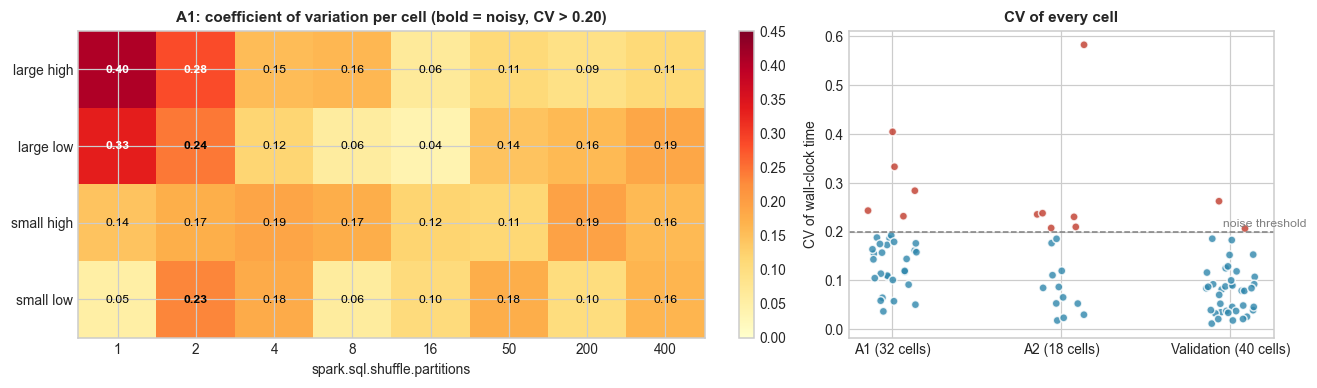

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
a1 = desc[desc["experiment_action"] == "A1"].pivot(index="workload_id", columns="shuffle_partitions", values="cv_wall")
im = axes[0].imshow(a1.to_numpy(), cmap="YlOrRd", vmin=0, vmax=0.45, aspect="auto")
axes[0].set_xticks(range(a1.shape[1]), a1.columns)
axes[0].set_yticks(range(a1.shape[0]), [label(w) for w in a1.index])
for i in range(a1.shape[0]):
    for j in range(a1.shape[1]):
        v = a1.iat[i, j]
        axes[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if v > 0.25 else "black", fontweight="bold" if v > sa.CV_THRESHOLD else None)
axes[0].set_xlabel("spark.sql.shuffle.partitions")
axes[0].set_title("A1: coefficient of variation per cell (bold = noisy, CV > 0.20)")
fig.colorbar(im, ax=axes[0], fraction=0.03)

for k, (action, g) in enumerate(desc.groupby("experiment_action")):
    x = np.full(len(g), k) + np.random.default_rng(1).uniform(-0.15, 0.15, len(g))
    axes[1].scatter(x, g["cv_wall"], c=np.where(g["noisy"], "#C0392B", "#2E86AB"), s=28, alpha=0.8, edgecolor="white")
axes[1].axhline(sa.CV_THRESHOLD, ls="--", c="gray", lw=1)
axes[1].text(2.45, sa.CV_THRESHOLD + 0.01, "noise threshold", ha="right", fontsize=8, color="gray")
axes[1].set_xticks([0, 1, 2], ["A1 (32 cells)", "A2 (18 cells)", "Validation (40 cells)"])
axes[1].set_ylabel("CV of wall-clock time")
axes[1].set_title("CV of every cell")
fig.tight_layout()
save(fig, "fig01_noise_cv")

**Reading.** Most cells are stable (median CV 0.16 for A1, 0.11 for A2, 0.08 for validation). The noisy cells are
*very short* runs — the 1- and 2-partition A1 runs (0.25–1.2 s) and the sub-second compaction jobs of A2 — where a
small absolute delay is a large relative change. They were kept (decision of 2026-10-23); Section 10 shows the
conclusions do not change when the slowest run of each noisy A1 cell is removed.

## 4. A1 — shuffle-partition tuning

Each A1 workload (10 input files) was run at 8 partition settings (1 … 400) in 5 randomised blocks. The static
default is **200**. The *speed-up* is median(default) / median(best). The *near-optimal set* (plateau) holds every
setting whose median is within 10% of the best median. Confidence intervals come from a block bootstrap
(10 000 resamples of the 5 blocks; the best setting is fixed from the full data).

### 4.1 The U-shaped cost curve

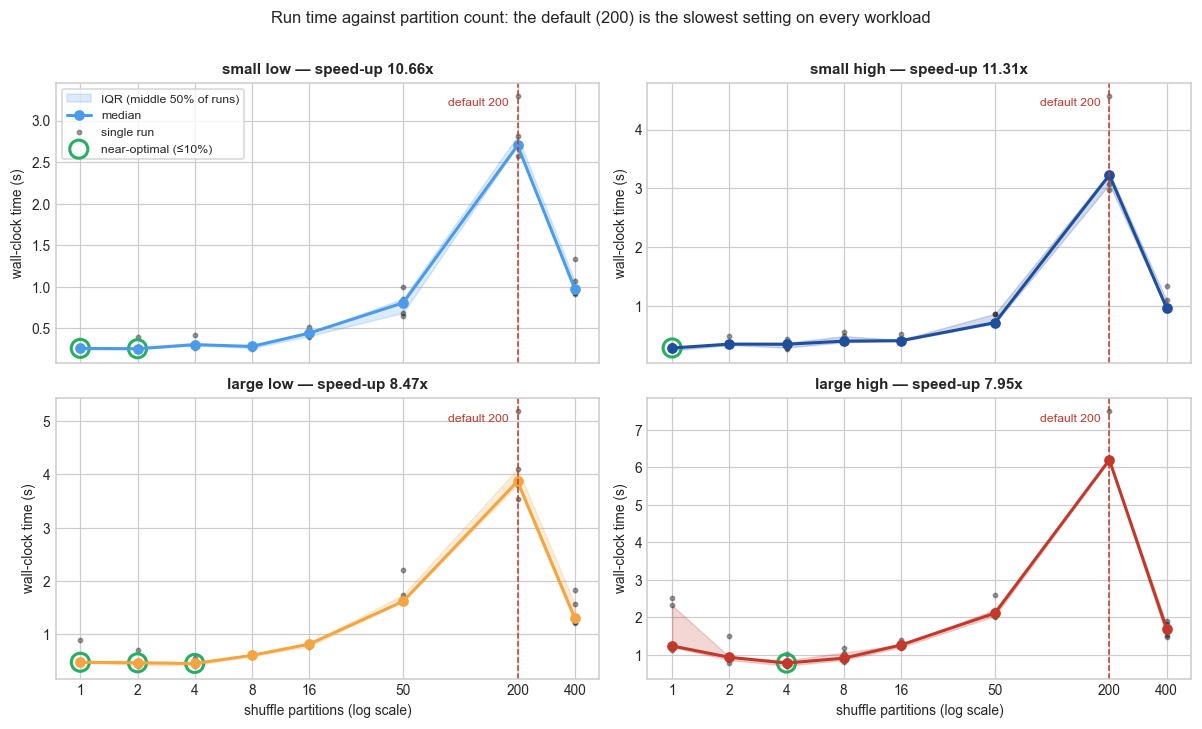

In [5]:
a1 = runs[runs["experiment_action"] == "A1"]
q = a1.groupby(["workload_id", "shuffle_partitions"])["wall_clock_seconds"].quantile([0.25, 0.5, 0.75]).unstack()
eff = T["a1_effects"].set_index(["metric", "workload_id"])
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, w in zip(axes.flat, ["A1_small_low", "A1_small_high", "A1_large_low", "A1_large_high"]):
    d = q.loc[w]
    c = WORKLOAD_COLORS[w]
    ax.fill_between(d.index, d[0.25], d[0.75], color=c, alpha=0.2, label="IQR (middle 50% of runs)")
    ax.plot(d.index, d[0.5], "o-", color=c, lw=2, label="median")
    pts = a1[a1["workload_id"] == w]
    ax.scatter(pts["shuffle_partitions"], pts["wall_clock_seconds"], s=8, color="black", alpha=0.35, label="single run")
    plateau = [int(p) for p in str(eff.loc[("wall", w), "plateau_partitions"]).split()]
    ax.scatter(plateau, d.loc[plateau, 0.5], s=140, facecolor="none", edgecolor="#27AE60", lw=2, label="near-optimal (≤10%)")
    ax.axvline(STATIC_PARTITIONS, color="#C0392B", ls="--", lw=1)
    ax.text(STATIC_PARTITIONS * 0.9, ax.get_ylim()[1] * 0.92, "default 200", ha="right", color="#C0392B", fontsize=8)
    ax.set_xscale("log", base=2)
    ax.set_xticks(d.index, d.index)
    ax.set_title(f"{label(w)} — speed-up {eff.loc[('wall', w), 'speedup']:.2f}x")
    ax.set_ylabel("wall-clock time (s)")
for ax in axes[1]:
    ax.set_xlabel("shuffle partitions (log scale)")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Run time against partition count: the default (200) is the slowest setting on every workload", y=1.01)
fig.tight_layout()
save(fig, "fig02_a1_ucurves")

**Reading.** The curve is not really a "U": time falls almost all the way down to 1–4 partitions because these
data sets are small for one machine, and every extra partition adds a task with fixed start-up overhead. The
default of 200 is the slowest of all eight settings on all four workloads.

### 4.2 Effect sizes with confidence intervals

In [6]:
cols = ["workload_id", "metric", "best_partitions", "plateau_partitions", "best_share_of_resamples", "speedup",
        "speedup_ci_low", "speedup_ci_high", "cliffs_delta", "wilcoxon_p_exact"]
display(T["a1_effects"][cols])

,workload_id,metric,best_partitions,plateau_partitions,best_share_of_resamples,speedup,speedup_ci_low,speedup_ci_high,cliffs_delta,wilcoxon_p_exact
0,A1_large_high,wall,4,4,1.000,7.948,7.264,8.747,1.0,0.062
1,A1_large_low,wall,4,1 2 4,0.885,8.470,7.423,11.090,1.0,0.062
2,A1_small_high,wall,1,1,0.943,11.314,10.412,13.415,1.0,0.062
3,A1_small_low,wall,2,1 2,0.687,10.661,8.240,11.112,1.0,0.062
4,A1_large_high,executor,1,1,0.682,24.451,13.434,30.862,1.0,0.062
5,A1_large_low,executor,1,1,1.000,39.010,25.051,43.379,1.0,0.062
6,A1_small_high,executor,1,1,1.000,71.589,57.983,73.902,1.0,0.062
7,A1_small_low,executor,1,1,1.000,66.173,59.073,81.543,1.0,0.062


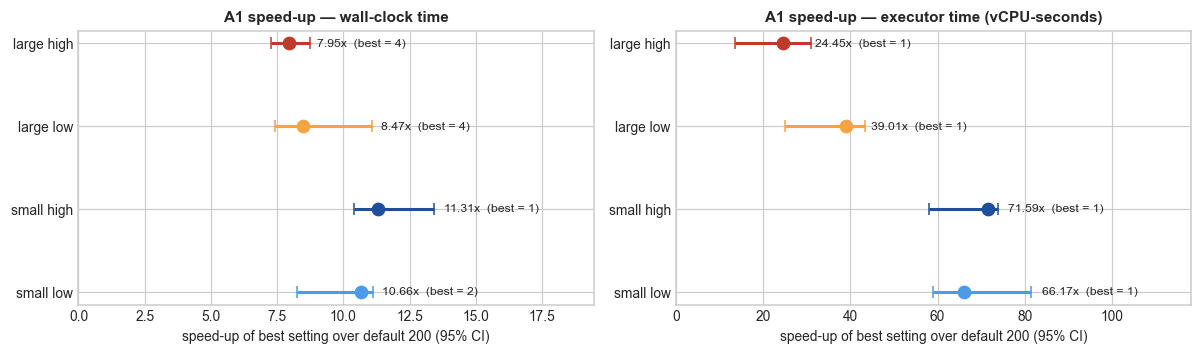

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
for ax, metric, title in zip(axes, ["wall", "executor"], ["wall-clock time", "executor time (vCPU-seconds)"]):
    e = T["a1_effects"][T["a1_effects"]["metric"] == metric].reset_index(drop=True)
    for i, r in e.iterrows():
        c = WORKLOAD_COLORS[r["workload_id"]]
        ax.errorbar(r["speedup"], i, xerr=[[r["speedup"] - r["speedup_ci_low"]], [r["speedup_ci_high"] - r["speedup"]]],
                    fmt="o", color=c, ms=8, capsize=4, lw=2)
        ax.text(r["speedup_ci_high"] * 1.03, i, f"{r['speedup']:.2f}x  (best = {r['best_partitions']})", va="center", fontsize=8)
    ax.set_yticks(range(len(e)), [label(w) for w in e["workload_id"]])
    ax.set_xlabel("speed-up of best setting over default 200 (95% CI)")
    ax.set_title(f"A1 speed-up — {title}")
    ax.set_xlim(left=0, right=e["speedup_ci_high"].max() * 1.45)
    ax.invert_yaxis()
fig.tight_layout()
save(fig, "fig03_a1_speedup_ci")

**Reading.** Every interval sits far above 1, so tuning is clearly worthwhile on every workload; Cliff's delta is
+1 (every default run is slower than every best run). The exact Wilcoxon p-value is 0.0625 everywhere — that is
the smallest value the test can give with 5 pairs, not a weak result.

### 4.3 Does the benefit *differ* between workloads? (pre-registered H1 test for A1)

H1 for A1 is met when, for at least one pair of workloads, the 95% intervals of the speed-up **do not overlap**
and the difference is **at least 15%**. As a stricter check we also bootstrap the *ratio* of the two speed-ups
with a Bonferroni-corrected interval (6 pairs), and we check whether the near-optimal sets are disjoint
(i.e. the best setting itself depends on the workload).

In [8]:
cols = ["metric", "workload_a", "workload_b", "speedup_a", "speedup_b", "cis_overlap", "relative_difference",
        "ratio_ci_low", "ratio_ci_high", "ratio_ci_bonferroni_excludes_1", "meets_h1_speedup", "plateaus_disjoint"]
display(T["a1_pairwise"][cols])

,metric,workload_a,workload_b,speedup_a,speedup_b,cis_overlap,relative_difference,ratio_ci_low,ratio_ci_high,ratio_ci_bonferroni_excludes_1,meets_h1_speedup,plateaus_disjoint
0,wall,A1_large_high,A1_large_low,7.948,8.470,True,0.066,0.670,1.178,False,False,False
1,wall,A1_large_high,A1_small_high,7.948,11.314,False,0.424,0.554,0.738,True,True,True
2,wall,A1_large_high,A1_small_low,7.948,10.661,True,0.341,0.701,0.902,True,False,True
3,wall,A1_large_low,A1_small_high,8.470,11.314,True,0.336,0.554,0.892,True,False,False
4,wall,A1_large_low,A1_small_low,8.470,10.661,True,0.259,0.695,1.346,False,False,False
5,wall,A1_small_high,A1_small_low,11.314,10.661,True,0.061,1.005,1.628,True,False,False
6,executor,A1_large_high,A1_large_low,24.451,39.010,True,0.595,0.310,0.885,True,False,False
7,executor,A1_large_high,A1_small_high,24.451,71.589,False,1.928,0.183,0.485,True,True,False
8,executor,A1_large_high,A1_small_low,24.451,66.173,False,1.706,0.198,0.522,True,True,False
9,executor,A1_large_low,A1_small_high,39.010,71.589,False,0.835,0.432,0.693,True,True,False


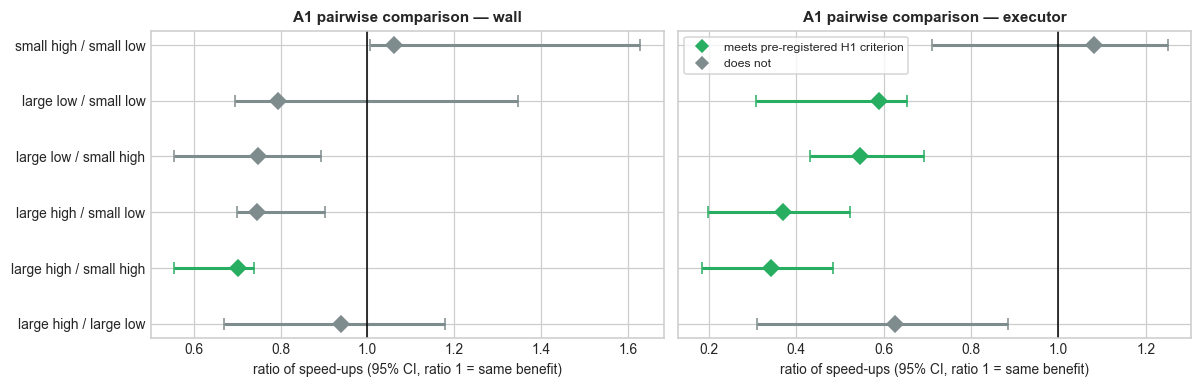

In [9]:
pw = T["a1_pairwise"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, metric in zip(axes, ["wall", "executor"]):
    p = pw[pw["metric"] == metric].reset_index(drop=True)
    for i, r in p.iterrows():
        c = "#27AE60" if r["meets_h1_speedup"] else "#7F8C8D"
        ratio = r["speedup_a"] / r["speedup_b"]
        ax.errorbar(ratio, i, xerr=[[ratio - r["ratio_ci_low"]], [r["ratio_ci_high"] - ratio]], fmt="D", color=c,
                    ms=7, capsize=4, lw=2)
    ax.axvline(1, color="black", lw=1)
    ax.set_yticks(range(len(p)), [f"{label(a)} / {label(b)}" for a, b in zip(p["workload_a"], p["workload_b"])])
    ax.set_xlabel("ratio of speed-ups (95% CI, ratio 1 = same benefit)")
    ax.set_title(f"A1 pairwise comparison — {metric}")
    ax.invert_yaxis()
axes[1].plot([], [], "D", color="#27AE60", label="meets pre-registered H1 criterion")
axes[1].plot([], [], "D", color="#7F8C8D", label="does not")
axes[1].legend(loc="upper left")
fig.tight_layout()
save(fig, "fig04_a1_pairwise_ratio")

In [10]:
for metric in ["wall", "executor"]:
    p = pw[pw["metric"] == metric]
    print(f"{metric:8s}: {int(p['meets_h1_speedup'].sum())}/6 pairs meet the CI criterion, "
          f"{int(p['ratio_ci_bonferroni_excludes_1'].sum())}/6 ratio CIs exclude 1, "
          f"{int(p['plateaus_disjoint'].sum())}/6 pairs have disjoint near-optimal sets")

wall    : 1/6 pairs meet the CI criterion, 4/6 ratio CIs exclude 1, 2/6 pairs have disjoint near-optimal sets
executor: 4/6 pairs meet the CI criterion, 5/6 ratio CIs exclude 1, 0/6 pairs have disjoint near-optimal sets


**Reading.** On wall-clock time one pair passes the pre-registered test: *small high-shuffle* (11.3x) vs
*large high-shuffle* (7.9x) — non-overlapping intervals and a 42% difference. Their near-optimal sets are also
disjoint (1 partition vs 4 partitions), so the best setting moves with data volume. On executor time four of six
pairs pass. **But** the practical decision never changes: for every workload the answer is "tune, and use a
small partition count". So the *size* of the benefit and the *exact* best setting depend on the workload, while
the *decision to tune* does not.

### 4.4 How stable is the best setting?

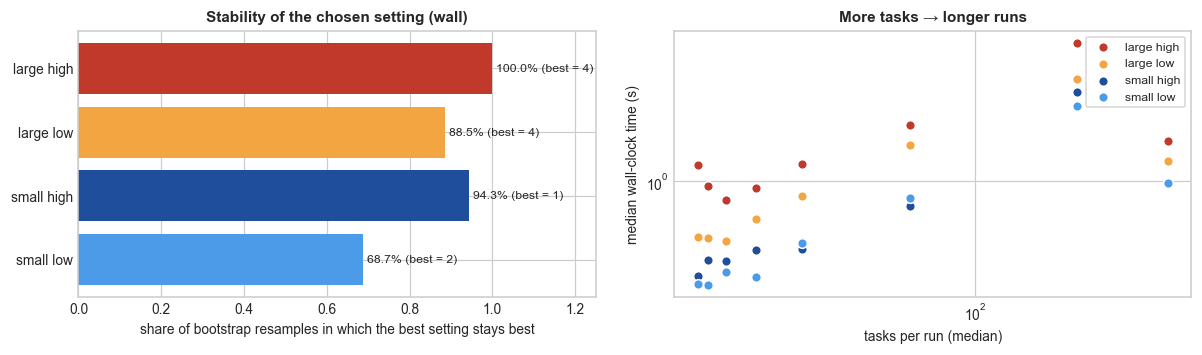

Spearman correlation between task count and run time over the 32 A1 cells: 0.70


In [11]:
e = T["a1_effects"][T["a1_effects"]["metric"] == "wall"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].barh([label(w) for w in e["workload_id"]], e["best_share_of_resamples"],
             color=[WORKLOAD_COLORS[w] for w in e["workload_id"]])
for i, (s, b) in enumerate(zip(e["best_share_of_resamples"], e["best_partitions"])):
    axes[0].text(s + 0.01, i, f"{pct(s)} (best = {b})", va="center", fontsize=8)
axes[0].set_xlim(0, 1.25)
axes[0].set_xlabel("share of bootstrap resamples in which the best setting stays best")
axes[0].set_title("Stability of the chosen setting (wall)")
axes[0].invert_yaxis()

for w, g in desc[desc["experiment_action"] == "A1"].groupby("workload_id"):
    axes[1].scatter(g["median_tasks"], g["median_wall_s"], s=40, color=WORKLOAD_COLORS[w], label=label(w), edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("tasks per run (median)")
axes[1].set_ylabel("median wall-clock time (s)")
axes[1].set_title("More tasks → longer runs")
axes[1].legend()
fig.tight_layout()
save(fig, "fig05_a1_stability_tasks")
rho = desc[desc["experiment_action"] == "A1"][["median_tasks", "median_wall_s"]].corr(method="spearman").iat[0, 1]
print(f"Spearman correlation between task count and run time over the 32 A1 cells: {rho:.2f}")

**Reading.** The best setting stays best in 69–100% of resamples. When it changes, it moves to a neighbouring
small count (1, 2 or 4 partitions) — never anywhere near the default. Run time grows with the number of tasks
(Spearman ρ = 0.70 over the 32 cells) — the main reason why 200 partitions are too many for these data sizes.

## 5. A2 — file compaction

Six workloads (small / large data × 1 / 10 / 50 input files, high shuffle) were run *before* compaction
(fragmented), *during* (the compaction job itself) and *after* (compacted input), in 5 blocks. The benefit is the
median over blocks of 1 − after / before.

### 5.1 Before vs after

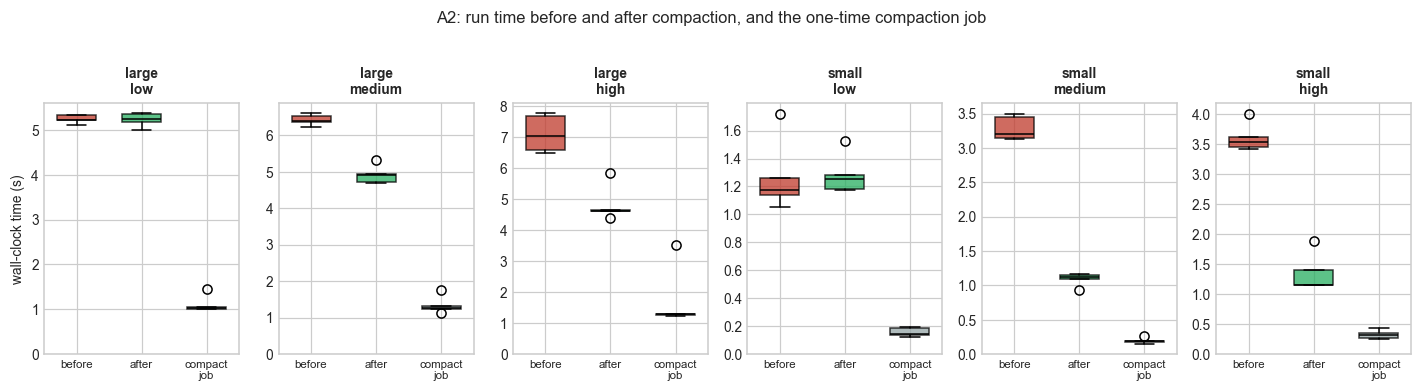

,workload_id,files,metric,median_before_s,median_after_s,median_copt_s,benefit_pct,benefit_ci_low,benefit_ci_high,blocks_after_faster,cliffs_delta,wilcoxon_p_exact
0,A2_large_low,1,wall,5.226,5.237,1.035,-0.003,-0.010,0.023,2,-0.12,1.000
1,A2_large_medium,10,wall,6.390,4.920,1.256,0.246,0.166,0.279,5,1.00,0.062
2,A2_large_high,50,wall,7.030,4.626,1.288,0.323,0.242,0.404,5,1.00,0.062
3,A2_small_low,1,wall,1.175,1.251,0.142,-0.017,-0.121,0.113,1,-0.36,0.625
4,A2_small_medium,10,wall,3.200,1.118,0.182,0.662,0.631,0.709,5,1.00,0.062
5,A2_small_high,50,wall,3.541,1.154,0.311,0.664,0.530,0.674,5,1.00,0.062
6,A2_large_low,1,executor,9.342,9.257,0.906,0.009,-0.166,0.055,4,0.12,0.625
7,A2_large_medium,10,executor,61.387,9.138,1.150,0.851,0.841,0.861,5,1.00,0.062
8,A2_large_high,50,executor,62.368,8.799,1.167,0.856,0.825,0.861,5,1.00,0.062
9,A2_small_low,1,executor,3.501,3.733,0.037,-0.077,-0.285,0.161,1,-0.60,0.625


In [12]:
a2 = runs[runs["experiment_action"] == "A2"].copy()
order = sa.a2_workloads(runs)["workload_id"].tolist()
fig, axes = plt.subplots(1, 6, figsize=(13, 3.4), sharey=False)
for ax, w in zip(axes, order):
    g = a2[a2["workload_id"] == w]
    data = [g[g["config_label"] == s]["wall_clock_seconds"] for s in ("fragmented", "compacted", "compaction")]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "black"})
    for patch, c in zip(bp["boxes"], ["#C0392B", "#27AE60", "#95A5A6"]):
        patch.set_facecolor(c)
        patch.set_alpha(0.75)
    ax.set_xticks([1, 2, 3], ["before", "after", "compact\njob"], fontsize=7.5)
    ax.set_title(label(w).replace(" ", "\n", 1), fontsize=9)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("wall-clock time (s)")
fig.suptitle("A2: run time before and after compaction, and the one-time compaction job", y=1.03)
fig.tight_layout()
save(fig, "fig06_a2_before_after")
cols = ["workload_id", "files", "metric", "median_before_s", "median_after_s", "median_copt_s", "benefit_pct",
        "benefit_ci_low", "benefit_ci_high", "blocks_after_faster", "cliffs_delta", "wilcoxon_p_exact"]
display(T["a2_effects"][cols])

### 5.2 Benefit against the number of input files (H1 for A2)

H1 for A2 needs the benefit to rise from 1 → 10 → 50 files, and the high-fragmentation benefit to be clearly
above the noise floor (its 95% interval lower bound above 10%). The open black markers are the four validation
workloads, which were never used to build the framework.

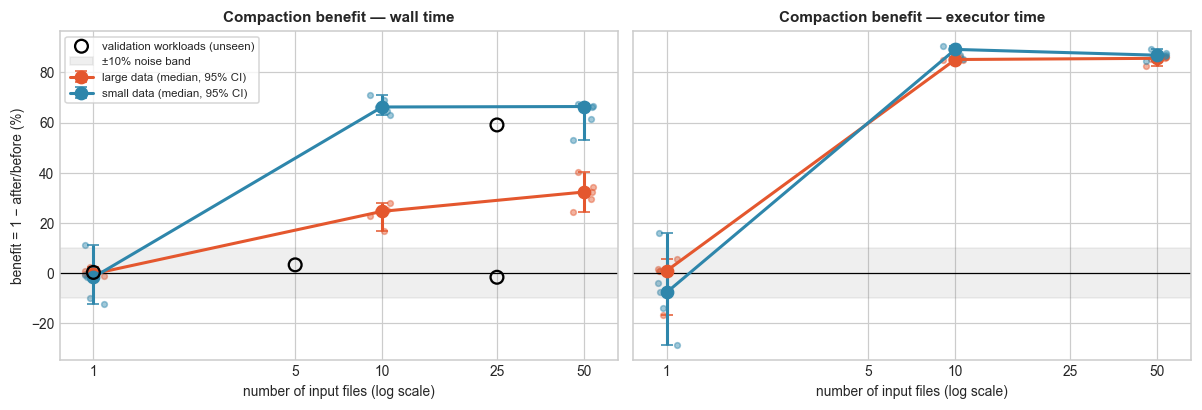

,metric,data_volume,benefit_1_file,benefit_10_files,benefit_50_files,monotonic,monotonic_share_of_resamples,gain_1_to_10_ci_low,gain_1_to_10_ci_high,gain_10_to_50,gain_10_to_50_ci_low,gain_10_to_50_ci_high,high_ci_low,high_above_noise_floor,spearman_rho,spearman_p_permutation
0,wall,large,-0.003,0.246,0.323,True,1.000,0.143,0.289,0.077,0.044,0.178,0.242,True,0.888,2.000e-04
1,wall,small,-0.017,0.662,0.664,True,0.494,0.549,0.789,0.002,-0.158,0.033,0.530,True,0.643,5.899e-03
2,executor,large,0.009,0.851,0.856,True,0.885,0.796,1.006,0.005,-0.016,0.011,0.825,True,0.775,5.999e-04
3,executor,small,-0.077,0.892,0.869,False,0.325,0.730,1.138,-0.023,-0.059,0.024,0.847,True,0.624,7.799e-03


In [13]:
val = decisions[decisions["proxy"] == "P1"].drop_duplicates("workload_id")[["workload_id", "measured_saving_compact"]]
val["files"] = val["workload_id"].str.extract(r"_(\d+)f_").astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, ["wall", "executor"]):
    col = sa.METRICS[metric]
    e = T["a2_effects"][T["a2_effects"]["metric"] == metric]
    for vol, g in e.groupby("data_volume"):
        c = VOLUME_COLORS[vol]
        ax.errorbar(g["files"], g["benefit_pct"] * 100,
                    yerr=[(g["benefit_pct"] - g["benefit_ci_low"]) * 100, (g["benefit_ci_high"] - g["benefit_pct"]) * 100],
                    fmt="o-", color=c, ms=8, capsize=4, lw=2, label=f"{vol} data (median, 95% CI)")
        for w, files in zip(g["workload_id"], g["files"]):
            m = sa._matrix(runs, "A2", w, col, "config_label")
            per_block = (1 - m["compacted"] / m["fragmented"]) * 100
            jitter = np.random.default_rng(len(w)).uniform(0.9, 1.1, len(per_block))
            ax.scatter(files * jitter, per_block, s=14, color=c, alpha=0.45)
    if metric == "wall":
        ax.scatter(val["files"], val["measured_saving_compact"] * 100, s=70, facecolor="none", edgecolor="black", lw=1.5,
                   label="validation workloads (unseen)", zorder=5)
    ax.axhspan(-100 * sa.NOISE_FLOOR, 100 * sa.NOISE_FLOOR, color="gray", alpha=0.12, label="±10% noise band")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xscale("log")
    ax.set_xticks([1, 5, 10, 25, 50], [1, 5, 10, 25, 50])
    ax.set_xlabel("number of input files (log scale)")
    ax.set_title(f"Compaction benefit — {metric} time")
axes[0].set_ylabel("benefit = 1 − after/before (%)")
axes[0].legend(loc="upper left", fontsize=7.5)
fig.tight_layout()
save(fig, "fig07_a2_benefit_vs_files")
cols = ["metric", "data_volume", "benefit_1_file", "benefit_10_files", "benefit_50_files", "monotonic",
        "monotonic_share_of_resamples", "gain_1_to_10_ci_low", "gain_1_to_10_ci_high", "gain_10_to_50",
        "gain_10_to_50_ci_low", "gain_10_to_50_ci_high", "high_ci_low", "high_above_noise_floor", "spearman_rho",
        "spearman_p_permutation"]
display(T["a2_trend"][cols])

**Reading.** With 1 file compaction does nothing (benefit within ±2%, interval straddles zero). Going from 1 to
10 files the benefit jumps (to about 25% on large data and 66% on small data); this jump is certain — its
interval is far from zero. From 10 to 50 files the benefit grows further on large data (+7.7 points, interval
+4.4 to +17.8) but **levels off** on small data (+0.2 points, interval −15.8 to +3.3). So the honest statement is:
*the benefit rises with fragmentation and then saturates* — not a strict increase at every step. The validation
workloads (open markers) fall on the same pattern: ~0 for 1 file, large for 25 files.

## 6. Cost and break-even with uncertainty

Cost is computed with two proxies: **P1** = wall-clock time × 12 vCPUs (the laptop's 12 hardware threads) × price,
**P2** = executor run time × price (price \$0.0505 per vCPU-hour, AWS m6i on-demand). Total cost after N runs is TC(N) = Copt + N · Crun, and the break-even point is
N\* = ⌈Copt / ΔC⌉, where ΔC is the saving per run. For A1 the one-time cost Copt is the full search over all
8 settings. The bootstrap gives an interval for the saving, for Copt / Crun(static) and for N\* itself.

In [14]:
be = T["breakeven"]
display(be)

,workload_id,action,proxy,saving_pct,saving_ci_low,saving_ci_high,copt_ratio,copt_ratio_ci_low,copt_ratio_ci_high,n_star,n_star_share_same,n_star_mode,n_star_min,n_star_max,n_star_share_finite
0,A1_large_high,A1_search,P1,0.874,0.862,0.886,2.440,2.370,2.755,3.0,0.856,3.0,3.0,4.0,1.000
1,A1_large_low,A1_search,P1,0.882,0.865,0.910,2.490,2.450,2.598,3.0,1.000,3.0,3.0,3.0,1.000
2,A1_small_high,A1_search,P1,0.912,0.904,0.925,2.078,1.911,2.246,3.0,1.000,3.0,3.0,3.0,1.000
3,A1_small_low,A1_search,P1,0.906,0.879,0.910,2.229,2.083,2.345,3.0,1.000,3.0,3.0,3.0,1.000
4,A2_large_low,A2,P1,-0.002,-0.010,0.023,0.198,0.188,0.273,inf,0.687,inf,9.0,inf,0.313
5,A2_large_medium,A2,P1,0.230,0.166,0.279,0.197,0.174,0.266,1.0,0.885,1.0,1.0,2.0,1.000
6,A2_large_high,A2,P1,0.342,0.242,0.404,0.183,0.158,0.457,1.0,0.943,1.0,1.0,2.0,1.000
7,A2_small_low,A2,P1,-0.065,-0.121,0.113,0.121,0.102,0.152,inf,0.942,inf,1.0,inf,0.058
8,A2_small_medium,A2,P1,0.651,0.631,0.709,0.057,0.047,0.078,1.0,1.000,1.0,1.0,1.0,1.000
9,A2_small_high,A2,P1,0.674,0.530,0.674,0.088,0.073,0.109,1.0,1.000,1.0,1.0,1.0,1.000


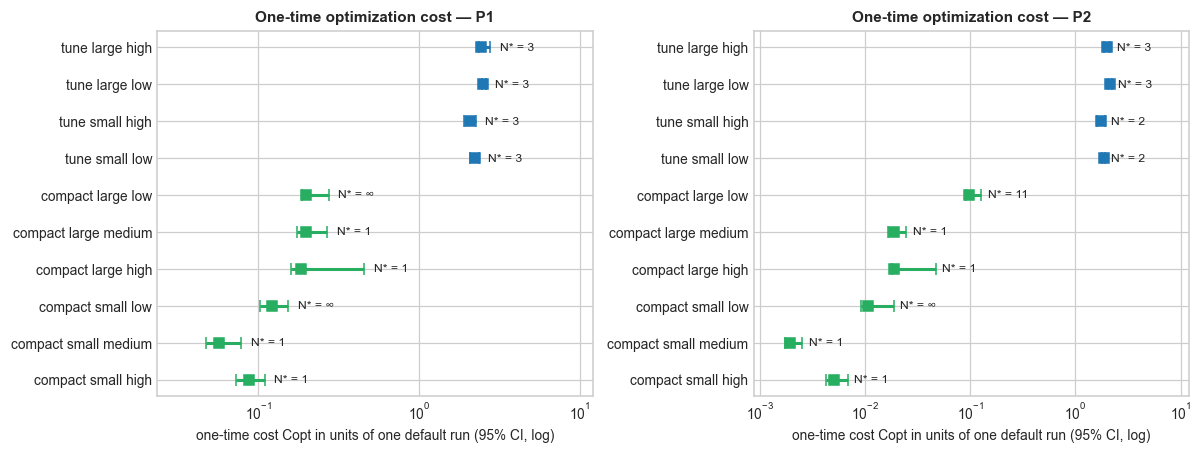

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, proxy in zip(axes, ["P1", "P2"]):
    b = be[be["proxy"] == proxy].reset_index(drop=True)
    for i, r in b.iterrows():
        c = "#1F77B4" if r["action"] == "A1_search" else "#27AE60"
        ax.errorbar(r["copt_ratio"], i, xerr=[[r["copt_ratio"] - r["copt_ratio_ci_low"]], [r["copt_ratio_ci_high"] - r["copt_ratio"]]],
                    fmt="s", color=c, ms=7, capsize=4, lw=2)
        n = "∞" if np.isinf(r["n_star"]) else int(r["n_star"])
        ax.text(r["copt_ratio_ci_high"] * 1.15, i, f"N* = {n}", va="center", fontsize=8)
    ax.set_xscale("log")
    ax.set_yticks(range(len(b)), [("tune " if a == "A1_search" else "compact ") + label(w) for w, a in zip(b["workload_id"], b["action"])])
    ax.set_xlabel("one-time cost Copt in units of one default run (95% CI, log)")
    ax.set_title(f"One-time optimization cost — {proxy}")
    ax.set_xlim(b["copt_ratio_ci_low"].min() * 0.5, 12)
    ax.invert_yaxis()
fig.tight_layout()
save(fig, "fig08_copt_ratio_ci")

**Reading.** A1's search costs about 1.8–2.5 default runs (every setting is tried once), while compaction costs only
0.06–0.2 of a run. Because the saving per run is large in both cases, N\* is small: 3 runs for the A1 search
(2 under P2 on small data) and 1 run for compaction on fragmented input. Compaction on a single file never pays
back (N\* = ∞) because there is nothing to save.

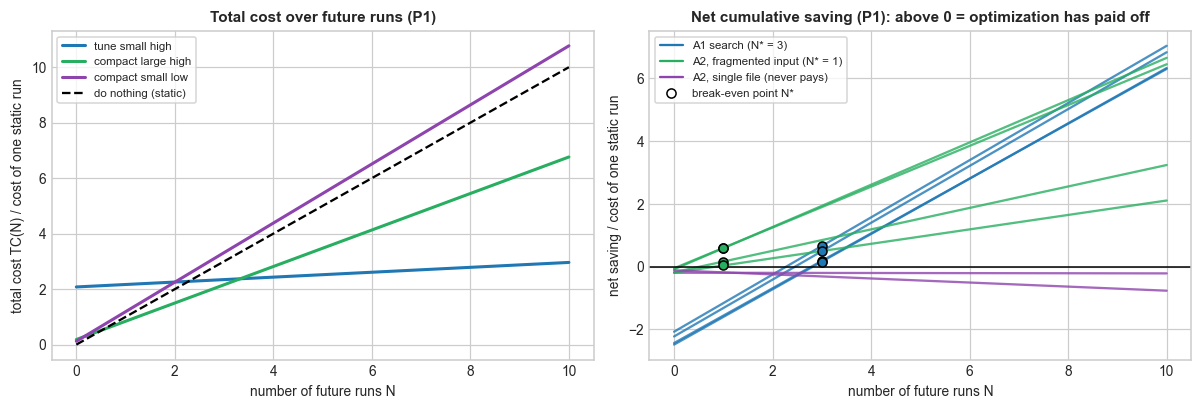

In [16]:
p1 = breakeven[(breakeven["proxy"] == "P1") & breakeven["action"].isin(["A1_search", "A2"])]
N = np.arange(0, 11)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
examples = [("A1_small_high", "A1_search"), ("A2_large_high", "A2"), ("A2_small_low", "A2")]
for (w, a), c in zip(examples, ["#1F77B4", "#27AE60", "#8E44AD"]):
    r = p1[(p1["workload_id"] == w) & (p1["action"] == a)].iloc[0]
    k = r["crun_static_usd"]
    axes[0].plot(N, (r["copt_usd"] + N * r["crun_action_usd"]) / k, "-", color=c, lw=2,
                 label=f"{'tune' if a == 'A1_search' else 'compact'} {label(w)}")
axes[0].plot(N, N, "k--", lw=1.5, label="do nothing (static)")
axes[0].set_xlabel("number of future runs N")
axes[0].set_ylabel("total cost TC(N) / cost of one static run")
axes[0].set_title("Total cost over future runs (P1)")
axes[0].legend(fontsize=7.5)

for _, r in p1.iterrows():
    k = r["crun_static_usd"]
    net = (N * r["saving_per_run_usd"] - r["copt_usd"]) / k
    c = "#1F77B4" if r["action"] == "A1_search" else ("#27AE60" if r["saving_pct"] > sa.NOISE_FLOOR else "#8E44AD")
    axes[1].plot(N, net, color=c, alpha=0.8, lw=1.5)
    if np.isfinite(r["n_star"]):
        n = int(r["n_star"])
        axes[1].scatter(n, (n * r["saving_per_run_usd"] - r["copt_usd"]) / k, color=c, s=35, zorder=5, edgecolor="black")
axes[1].axhline(0, color="black", lw=1)
axes[1].plot([], [], color="#1F77B4", label="A1 search (N* = 3)")
axes[1].plot([], [], color="#27AE60", label="A2, fragmented input (N* = 1)")
axes[1].plot([], [], color="#8E44AD", label="A2, single file (never pays)")
axes[1].scatter([], [], color="white", edgecolor="black", label="break-even point N*")
axes[1].set_xlabel("number of future runs N")
axes[1].set_ylabel("net saving / cost of one static run")
axes[1].set_title("Net cumulative saving (P1): above 0 = optimization has paid off")
axes[1].legend(fontsize=7.5)
fig.tight_layout()
save(fig, "fig09_total_cost_and_net_saving")

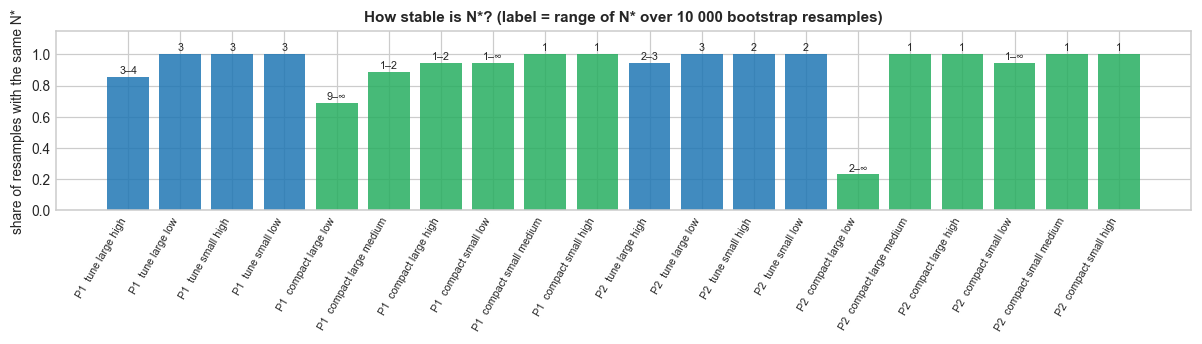

In [17]:
fig, ax = plt.subplots(figsize=(11, 3.2))
b = be.copy()
b["name"] = b["proxy"] + "  " + np.where(b["action"] == "A1_search", "tune ", "compact ") + b["workload_id"].map(label)
colors = np.where(b["action"] == "A1_search", "#1F77B4", "#27AE60")
ax.bar(range(len(b)), b["n_star_share_same"], color=colors, alpha=0.85)
for i, r in b.iterrows():
    rng = "∞" if np.isinf(r["n_star_min"]) else f"{int(r['n_star_min'])}" + ("" if r["n_star_min"] == r["n_star_max"] else
          ("–∞" if np.isinf(r["n_star_max"]) else f"–{int(r['n_star_max'])}"))
    ax.text(i, r["n_star_share_same"] + 0.02, rng, ha="center", fontsize=7)
ax.set_xticks(range(len(b)), b["name"], rotation=60, ha="right", fontsize=7)
ax.set_ylim(0, 1.15)
ax.set_ylabel("share of resamples with the same N*")
ax.set_title("How stable is N*? (label = range of N* over 10 000 bootstrap resamples)")
fig.tight_layout()
save(fig, "fig10_nstar_stability")

**Reading.** N\* is very stable. The A1 search value of 3 (or 2) moves by at most one run across resamples, and
compaction on fragmented input pays back after 1 run (at most 2) in every resample. The only unstable cases
are the single-file compaction rows, where the true saving is about zero and the sign of a tiny saving flips
with the noise (under P2 the large single-file point estimate is N\* = 11, but in 26% of resamples it never pays).
That is exactly the "do not optimize" case the framework should detect.

## 7. Data volume vs run time — default vs best

How does run time grow with the number of orders, and does tuning help at every size? Training workloads (A1)
and validation workloads are shown together.

,set,workload_id,orders,default_s,best_s,best_partitions
3,training,A1_small_low,50000,2.702,0.253,2
2,training,A1_small_high,50000,3.227,0.285,1
7,validation,V_small_25f_s15,50000,2.853,0.327,4
5,validation,V_medium_1f_s85,500000,4.096,0.514,2
6,validation,V_medium_25f_s50,500000,3.825,0.534,2
1,training,A1_large_low,2000000,3.870,0.457,4
0,training,A1_large_high,2000000,6.201,0.780,4
4,validation,V_large_5f_s50,2000000,5.175,0.808,2


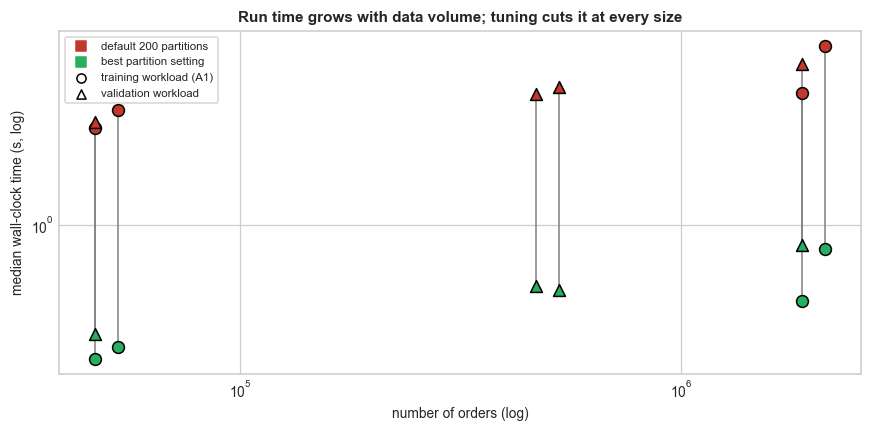

In [18]:
rows = []
for action, g in runs[runs["experiment_action"].isin(["A1", "VAL"])].groupby(["experiment_action", "workload_id"]):
    g = g[g["config_label"].str.startswith("shuffle")]
    med = g.groupby("shuffle_partitions")["wall_clock_seconds"].median()
    rows.append({"set": "validation" if action[0] == "VAL" else "training", "workload_id": action[1],
                 "orders": g["num_orders"].iloc[0], "default_s": med[STATIC_PARTITIONS], "best_s": med.min(),
                 "best_partitions": int(med.idxmin())})
vol = pd.DataFrame(rows).sort_values("orders")
display(vol)
fig, ax = plt.subplots(figsize=(8, 4))
for _, r in vol.iterrows():
    jitter = 1.06 if "high" in r["workload_id"] or "s85" in r["workload_id"] else 0.94
    x = r["orders"] * jitter
    ax.plot([x, x], [r["best_s"], r["default_s"]], color="gray", lw=1, zorder=1)
    m = "o" if r["set"] == "training" else "^"
    ax.scatter(x, r["default_s"], marker=m, s=60, color="#C0392B", edgecolor="black", zorder=3)
    ax.scatter(x, r["best_s"], marker=m, s=60, color="#27AE60", edgecolor="black", zorder=3)
ax.scatter([], [], marker="s", color="#C0392B", label="default 200 partitions")
ax.scatter([], [], marker="s", color="#27AE60", label="best partition setting")
ax.scatter([], [], marker="o", color="white", edgecolor="black", label="training workload (A1)")
ax.scatter([], [], marker="^", color="white", edgecolor="black", label="validation workload")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("number of orders (log)")
ax.set_ylabel("median wall-clock time (s, log)")
ax.set_title("Run time grows with data volume; tuning cuts it at every size")
ax.legend(fontsize=7.5)
fig.tight_layout()
save(fig, "fig11_orders_vs_time")

**Reading.** At every data size the best setting is far below the default; the gap is largest on the small
data sets, where the fixed per-task overhead of 200 partitions dominates the actual work. The validation
workloads (triangles), including the 2-million-order one, follow the same pattern.

## 8. Shuffle volume vs best partition count

Does more shuffled data need more partitions? For each workload we plot the shuffled megabytes (at the default
setting) against the best partition count, with a bar over the near-optimal range (within 10% of the best).

,set,workload_id,shuffle_mb,best,near_min,near_max
7,validation,V_small_25f_s15,0.332,4,4,8
3,training,A1_small_low,0.342,2,1,2
2,training,A1_small_high,1.108,1,1,1
6,validation,V_medium_25f_s50,5.437,2,2,4
1,training,A1_large_low,6.857,4,1,4
5,validation,V_medium_1f_s85,8.313,2,2,4
4,validation,V_large_5f_s50,20.386,2,2,8
0,training,A1_large_high,34.785,4,4,4


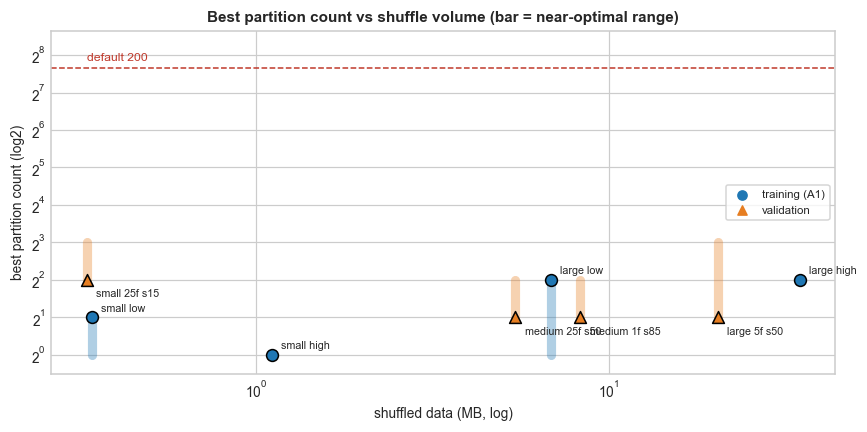

Spearman correlation between shuffle MB and best partition count (8 workloads): 0.14


In [19]:
rows = []
for action, g in runs[runs["experiment_action"].isin(["A1", "VAL"])].groupby(["experiment_action", "workload_id"]):
    g = g[g["config_label"].str.startswith("shuffle")]
    med = g.groupby("shuffle_partitions")["wall_clock_seconds"].median()
    near = med[med <= med.min() * (1 + sa.NOISE_FLOOR)].index
    rows.append({"set": "validation" if action[0] == "VAL" else "training", "workload_id": action[1],
                 "shuffle_mb": g[g["shuffle_partitions"] == STATIC_PARTITIONS]["shuffle_mb"].median(),
                 "best": int(med.idxmin()), "near_min": int(near.min()), "near_max": int(near.max())})
sh = pd.DataFrame(rows).sort_values("shuffle_mb")
display(sh)
fig, ax = plt.subplots(figsize=(8, 4))
for _, r in sh.iterrows():
    c = "#1F77B4" if r["set"] == "training" else "#E67E22"
    ax.plot([r["shuffle_mb"]] * 2, [r["near_min"], r["near_max"]], color=c, lw=6, alpha=0.35, solid_capstyle="round")
    ax.scatter(r["shuffle_mb"], r["best"], color=c, s=60, edgecolor="black", zorder=3,
               marker="o" if r["set"] == "training" else "^")
    ax.annotate(label(r["workload_id"]), (r["shuffle_mb"], r["best"]), fontsize=7, textcoords="offset points",
                xytext=(6, 4) if r["set"] == "training" else (6, -11))
ax.axhline(STATIC_PARTITIONS, color="#C0392B", ls="--", lw=1)
ax.text(sh["shuffle_mb"].min(), STATIC_PARTITIONS * 1.15, "default 200", color="#C0392B", fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log", base=2)
ax.set_ylim(0.7, 400)
ax.set_xlabel("shuffled data (MB, log)")
ax.set_ylabel("best partition count (log2)")
ax.set_title("Best partition count vs shuffle volume (bar = near-optimal range)")
ax.scatter([], [], color="#1F77B4", label="training (A1)")
ax.scatter([], [], color="#E67E22", marker="^", label="validation")
ax.legend(fontsize=7.5)
fig.tight_layout()
save(fig, "fig12_shuffle_vs_partitions")
rho = sh[["shuffle_mb", "best"]].corr(method="spearman").iat[0, 1]
print(f"Spearman correlation between shuffle MB and best partition count (8 workloads): {rho:.2f}")

**Reading.** There is no clear link between shuffle volume and the best count in our range (Spearman ρ is close to
zero): the best count stays between 1 and 8 partitions, two orders of magnitude below the default of 200, across
the whole range we tested. So "fewer partitions for small shuffles" is the rule here, not a smooth formula. Larger shuffles would be needed
to see where the default becomes right; this is a limit of a single-machine study.

## 9. H2 — framework validation on unseen workloads

The framework was frozen before the four validation workloads were run. For each workload, each proxy and each
planning horizon N ∈ {1, 5, 10, 50} it picked *do nothing*, *tune* or *compact*. We compare its measured total
cost with: **static** (always do nothing — the baseline of H2), **performance-only** (always apply the fastest
action and ignore its one-time cost) and the **oracle** (the best choice in hindsight). That gives 16 cases per
proxy. A *tie* means within 10% of static.

In [20]:
cols = ["proxy", "cases", "wins", "ties", "losses", "no_worse_share", "mean_reduction", "mean_ci_case_low",
        "mean_ci_case_high", "mean_ci_workload_low", "mean_ci_workload_high", "total_cost_reduction",
        "wilcoxon_p_one_sided", "sign_test_p_one_sided", "mean_gain_vs_performance_only",
        "gain_vs_performance_only_ci_low", "gain_vs_performance_only_ci_high", "mean_gap_to_oracle", "matches_oracle"]
display(T["h2_tests"][cols])

,proxy,cases,wins,ties,losses,no_worse_share,mean_reduction,mean_ci_case_low,mean_ci_case_high,mean_ci_workload_low,mean_ci_workload_high,total_cost_reduction,wilcoxon_p_one_sided,sign_test_p_one_sided,mean_gain_vs_performance_only,gain_vs_performance_only_ci_low,gain_vs_performance_only_ci_high,mean_gap_to_oracle,matches_oracle
0,P1,16,13,1,2,0.875,0.473,0.305,0.623,0.388,0.583,0.741,1.526e-04,3.693e-03,0.408,0.098,0.773,0.024,14
1,P2,16,15,1,0,1.000,0.722,0.596,0.818,0.576,0.836,0.879,3.052e-05,3.052e-05,0.490,0.148,0.903,0.004,14


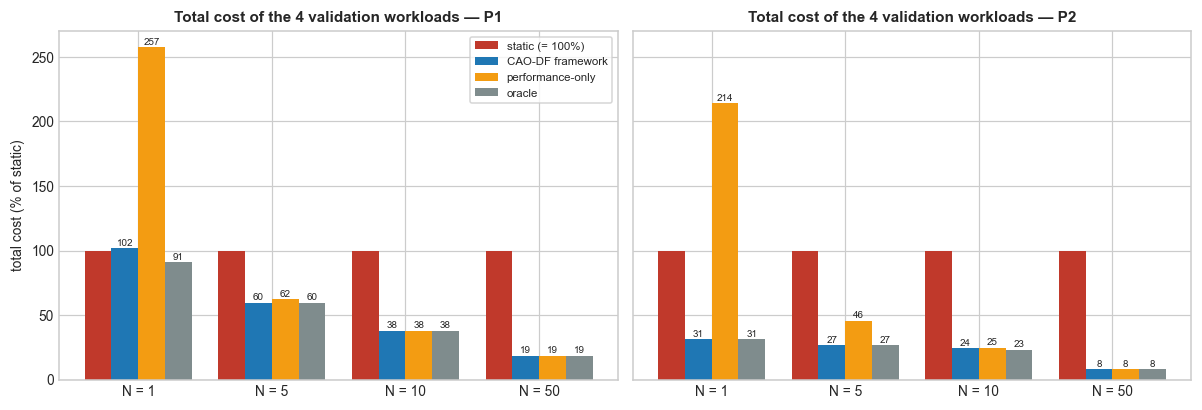

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
strategies = [("framework", "CAO-DF framework"), ("performance_only", "performance-only"), ("oracle", "oracle")]
for ax, proxy in zip(axes, ["P1", "P2"]):
    d = decisions[decisions["proxy"] == proxy]
    g = d.groupby("n_runs")
    x = np.arange(len(N_GRID))
    ax.bar(x - 0.3, 100, 0.2, color=STRATEGY_COLORS["static"], label="static (= 100%)")
    for k, (s, name) in enumerate(strategies):
        share = g[f"tc_{s}_usd"].sum() / g["tc_static_usd"].sum() * 100
        ax.bar(x - 0.1 + 0.2 * k, share.values, 0.2, color=STRATEGY_COLORS[s], label=name)
        for xi, v in zip(x - 0.1 + 0.2 * k, share.values):
            ax.text(xi, v + 2, f"{v:.0f}", ha="center", fontsize=6.5)
    ax.set_xticks(x, [f"N = {n}" for n in N_GRID])
    ax.set_title(f"Total cost of the 4 validation workloads — {proxy}")
axes[0].set_ylabel("total cost (% of static)")
axes[0].legend(fontsize=7.5, loc="upper right")
fig.tight_layout()
save(fig, "fig13_h2_strategy_costs")

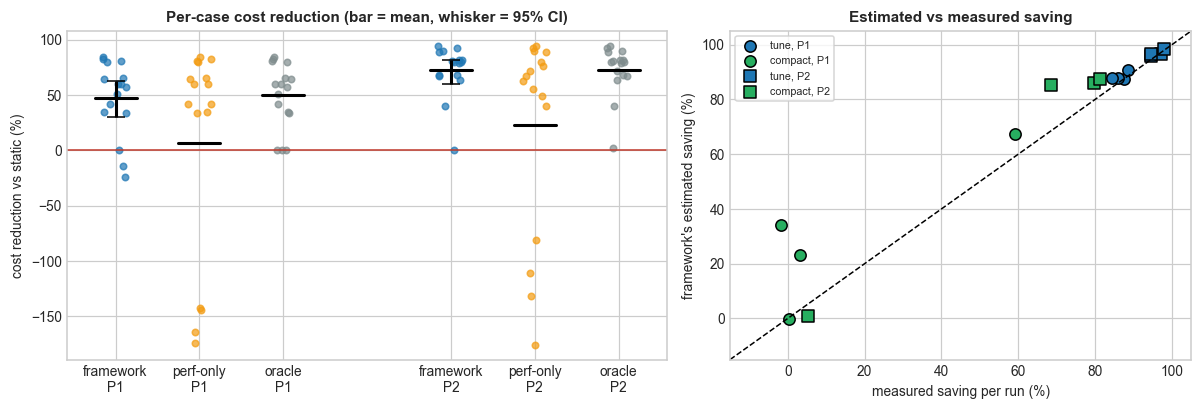

Estimate error over 16 (workload, proxy, action) pairs: median |error| = 2.8 points, max |error| = 35.9 points


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for k, proxy in enumerate(["P1", "P2"]):
    d = decisions[decisions["proxy"] == proxy]
    for j, (s, name) in enumerate(strategies):
        xs = k * 4 + j + np.random.default_rng(j).uniform(-0.15, 0.15, len(d))
        ax.scatter(xs, d[f"{s}_reduction_pct"] * 100, s=18, color=STRATEGY_COLORS[s], alpha=0.7)
        ax.plot([k * 4 + j - 0.25, k * 4 + j + 0.25], [d[f"{s}_reduction_pct"].mean() * 100] * 2, color="black", lw=2)
    t = T["h2_tests"].set_index("proxy").loc[proxy]
    ax.errorbar(k * 4, t["mean_reduction"] * 100, yerr=[[(t["mean_reduction"] - t["mean_ci_case_low"]) * 100],
                [(t["mean_ci_case_high"] - t["mean_reduction"]) * 100]], fmt="none", color="black", capsize=6, lw=2)
ax.axhline(0, color="#C0392B", lw=1)
ax.set_xticks([0, 1, 2, 4, 5, 6], ["framework\nP1", "perf-only\nP1", "oracle\nP1", "framework\nP2", "perf-only\nP2", "oracle\nP2"])
ax.set_ylabel("cost reduction vs static (%)")
ax.set_title("Per-case cost reduction (bar = mean, whisker = 95% CI)")

ax = axes[1]
first = decisions.drop_duplicates(["workload_id", "proxy"])
for proxy, mk in [("P1", "o"), ("P2", "s")]:
    f = first[first["proxy"] == proxy]
    ax.scatter(f["measured_saving_tune"] * 100, f["est_saving_tune"] * 100, marker=mk, s=55, color="#1F77B4",
               edgecolor="black", label=f"tune, {proxy}")
    ax.scatter(f["measured_saving_compact"] * 100, f["est_saving_compact"] * 100, marker=mk, s=55, color="#27AE60",
               edgecolor="black", label=f"compact, {proxy}")
lims = [-15, 105]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("measured saving per run (%)")
ax.set_ylabel("framework's estimated saving (%)")
ax.set_title("Estimated vs measured saving")
ax.legend(fontsize=7)
fig.tight_layout()
save(fig, "fig14_h2_reductions_estimates")
err = pd.concat([first["est_saving_tune"] - first["measured_saving_tune"],
                 first["est_saving_compact"] - first["measured_saving_compact"]])
print(f"Estimate error over 16 (workload, proxy, action) pairs: median |error| = {err.abs().median() * 100:.1f} points, "
      f"max |error| = {err.abs().max() * 100:.1f} points")

**Reading.** The framework is cheaper than static in 13 of 16 cases under P1 (1 tie, 2 losses) and 15 of 16
under P2 (1 tie, no loss). The mean reduction is 47.3% under P1 (95% CI 30.5–62.3%) and 72.2% under P2
(59.6–81.8%). Even the conservative interval that resamples whole workloads (only 4 of them) stays far above
zero. Performance-only does much worse at small N because it pays the full search cost even for a single run
(257% of the static cost at N = 1 under P1). From N = 5 on, the framework's total is within about one point of
the oracle; at
N = 1 under P1 its total is 2% above static because of the two losses explained below.
The estimated savings (from the nearest training workloads) are usually close to the measured ones (median error
of a few points), but one estimate is off by about 36 points — the nearest-neighbour estimate is coarse, yet the
*decision* it drives is still right in most cases because the savings are far from the break-even boundary.

In [23]:
losses = decisions[decisions["framework_vs_static"] == "loss"]
display(losses[["workload_id", "proxy", "n_runs", "framework_choice", "oracle_choice", "est_saving_tune",
                "measured_saving_tune", "est_saving_compact", "measured_saving_compact", "framework_reduction_pct"]])

,workload_id,proxy,n_runs,framework_choice,oracle_choice,est_saving_tune,measured_saving_tune,est_saving_compact,measured_saving_compact,framework_reduction_pct
8,V_medium_25f_s50,P1,1,Compact,Nothing,0.878,0.860,0.342,-0.017,-0.145
24,V_large_5f_s50,P1,1,Compact,Nothing,0.878,0.844,0.230,0.033,-0.239


**The losses.** The table above lists every case where the framework cost more than static. Both are under P1
at N = 1, and in both the framework chose *compact* because the nearest training workloads predicted a 23–34%
saving, while the real compaction saving on these moderately fragmented inputs (5 and 25 files at medium/large
volume) was about zero. Static was the right answer (oracle = do nothing). So the main weakness is the coarse
estimate of the compaction benefit between the trained file counts, and it only hurts when there is a single
run to recover the one-time cost.

### 9.1 Is the result robust to which validation block is used?

,block,proxy,wins,ties,losses,mean_reduction,total_cost_reduction
0,1,P1,13,1,2,0.463,0.738
1,1,P2,15,1,0,0.714,0.874
2,2,P1,13,1,2,0.473,0.751
3,2,P2,15,1,0,0.724,0.879
4,3,P1,13,1,2,0.481,0.754
5,3,P2,15,1,0,0.729,0.883


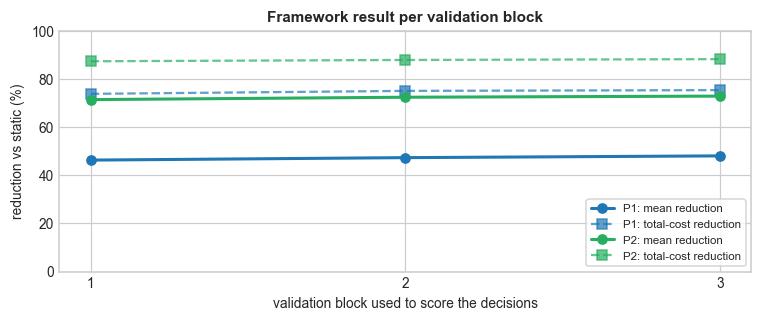

In [24]:
hb = T["h2_by_block"]
display(hb)
fig, ax = plt.subplots(figsize=(7, 3))
for proxy, c in [("P1", "#1F77B4"), ("P2", "#27AE60")]:
    g = hb[hb["proxy"] == proxy]
    ax.plot(g["block"], g["mean_reduction"] * 100, "o-", color=c, lw=2, label=f"{proxy}: mean reduction")
    ax.plot(g["block"], g["total_cost_reduction"] * 100, "s--", color=c, lw=1.5, alpha=0.7, label=f"{proxy}: total-cost reduction")
ax.set_xticks([1, 2, 3])
ax.set_xlabel("validation block used to score the decisions")
ax.set_ylabel("reduction vs static (%)")
ax.set_ylim(0, 100)
ax.set_title("Framework result per validation block")
ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
save(fig, "fig15_h2_by_block")

**Reading.** Scoring the same frozen decisions with each of the three validation blocks separately gives the same
win/tie/loss counts (13/1/2 and 15/1/0) and mean reductions within about ±1.5 points. The result does not
depend on a lucky block.

## 10. Sensitivity checks

### 10.1 Price
N\* is a ratio of costs, so the vCPU price cancels out. We re-ran the cost model with the price halved and
increased by 50%.

In [25]:
sens = pd.read_csv(PROCESSED / "cost_sensitivity.csv")
pivot = sens.pivot_table(index=["workload_id", "action", "proxy"], columns="price_factor", values="n_star", aggfunc="first")
changed = (pivot.nunique(axis=1) > 1).sum()
print(f"(workload, action, proxy) rows: {len(pivot)}; rows where N* changes with price: {changed}")
display(pivot.head(8))

(workload, action, proxy) rows: 28; rows where N* changes with price: 0


price_factor                   0.5  1.0  1.5
workload_id   action    proxy               
A1_large_high A1_rule   P1     1.0  1.0  1.0
                        P2     1.0  1.0  1.0
              A1_search P1     3.0  3.0  3.0
                        P2     3.0  3.0  3.0
A1_large_low  A1_rule   P1     1.0  1.0  1.0
                        P2     1.0  1.0  1.0
              A1_search P1     3.0  3.0  3.0
                        P2     3.0  3.0  3.0

### 10.2 Cost proxy (P1 vs P2)

In [26]:
bt = breakeven.pivot_table(index=["workload_id", "action"], columns="proxy", values="n_star", aggfunc="first")
agree = (bt["P1"] == bt["P2"]) | (np.isinf(bt["P1"]) & np.isinf(bt["P2"]))
print(f"N* agrees under P1 and P2 for {int(agree.sum())} of {len(bt)} (workload, action) pairs")
display(bt[~agree])

N* agrees under P1 and P2 for 11 of 14 (workload, action) pairs


,proxy,P1,P2
workload_id,action,,
A1_small_high,A1_search,3.0,2.0
A1_small_low,A1_search,3.0,2.0
A2_large_low,A2,inf,11.0


### 10.3 Noisy A1 cells
The slowest run of each noisy A1 cell was removed and the analysis repeated.

In [27]:
display(pd.read_csv(PROCESSED / "a1_outlier_robustness.csv"))

,workload_id,noisy_cells,best_partitions_full,best_partitions_trimmed,speedup_full,speedup_trimmed,spearman_rank_corr,max_cv_full,max_cv_trimmed
0,A1_large_high,2,4,4,7.948,7.948,0.976,0.404,0.385
1,A1_large_low,2,4,2,8.470,8.641,0.976,0.333,0.186
2,A1_small_high,0,1,1,11.314,11.314,1.000,0.192,0.192
3,A1_small_low,1,2,2,10.661,10.742,1.000,0.231,0.179


### 10.4 Tie tolerance δ of the framework
The framework treats savings within δ of zero as "no real gain". δ = 10% was fixed before validation. Here we
re-run the whole validation with other values.

In [28]:
profiles = dfw.training_profiles(PRICE, VCPUS)
cells_val = dfw.load_validation_cells(PRICE, VCPUS)
base = None
rows = []
for delta in [0.0, 0.05, 0.10, 0.20]:
    tab = dfw.validate(profiles, cells_val, delta)
    if base is None:
        base = tab
    s = dfw.summarize(tab)
    for _, r in s[s["strategy"] == "framework"].iterrows():
        rows.append({"delta": delta, "proxy": r["proxy"], "wins": r["wins"], "ties": r["ties"], "losses": r["losses"],
                     "mean_reduction": r["mean_reduction_pct"], "ci_low": r["ci95_low"], "ci_high": r["ci95_high"],
                     "choices_same_as_delta_0": int((tab["framework_choice"].values == base["framework_choice"].values)
                                                    [(tab["proxy"] == r["proxy"]).values].sum())})
delta_table = pd.DataFrame(rows)
display(delta_table)

,delta,proxy,wins,ties,losses,mean_reduction,ci_low,ci_high,choices_same_as_delta_0
0,0.00,P1,13,1,2,0.473,0.305,0.623,16
1,0.00,P2,15,1,0,0.722,0.596,0.818,16
2,0.05,P1,13,1,2,0.473,0.305,0.623,16
3,0.05,P2,15,1,0,0.722,0.596,0.818,16
4,0.10,P1,13,1,2,0.473,0.305,0.623,16
5,0.10,P2,15,1,0,0.722,0.596,0.818,16
6,0.20,P1,13,2,1,0.473,0.305,0.623,16
7,0.20,P2,15,1,0,0.722,0.596,0.818,16


### 10.5 Leave-one-out check of the training profiles
Each training workload was removed in turn and predicted from the others.

In [29]:
loo = pd.read_csv(PROCESSED / "framework_loo.csv")
print(f"Leave-one-out agreement: {loo['agree'].mean():.0%} of {len(loo)} predictions")
display(loo.groupby(["action", "proxy"])["agree"].mean().rename("agreement").to_frame())

Leave-one-out agreement: 80% of 80 predictions


agreement
action proxy           
A1     P1         1.000
       P2         1.000
A2     P1         0.667
       P2         0.667

**Reading.** N\* does not change with price, P1 and P2 agree on most break-even points, removing outliers from
the noisy cells leaves the best setting stable, and the framework makes exactly the same 32 choices for every δ
from 0 to 0.20 (only the tie count changes at δ = 0.20, because a tie is defined with δ). None of the
conclusions rests on a single analysis choice.

## 11. Hypothesis verdicts

The verdict rules were fixed in the master document (§9) before the data were analysed.

In [30]:
display(T["verdicts"].style.set_properties(subset=["evidence"], **{"text-align": "left", "white-space": "normal"}))

,hypothesis,metric,criterion,evidence,verdict
0,H1 (A1),wall,"Best setting or speed-up differs between >= 1 workload pair beyond noise (non-overlapping 95 % CIs, effect >= 15 %)","1/6 pairs meet the speed-up criterion; 2/6 pairs have disjoint near-optimal settings; speed-ups 7.95-11.31x, all 5/5 blocks faster",Supported
1,H1 (A1),executor,"Best setting or speed-up differs between >= 1 workload pair beyond noise (non-overlapping 95 % CIs, effect >= 15 %)","4/6 pairs meet the speed-up criterion; 0/6 pairs have disjoint near-optimal settings; speed-ups 24.45-71.59x, all 5/5 blocks faster",Supported
2,H1 (A2),wall,Benefit rises monotonically with file count (1 -> 10 -> 50); 50-file benefit outside the noise band,large: -0.3% -> 24.6% -> 32.3% (10->50 gain CI +4.4% to +17.8%); small: -1.7% -> 66.2% -> 66.4% (10->50 gain CI -15.8% to +3.3%); benefit range -1.7% to 66.4%,Supported
3,H1 (A2),executor,Benefit rises monotonically with file count (1 -> 10 -> 50); 50-file benefit outside the noise band,large: 0.9% -> 85.1% -> 85.6% (10->50 gain CI -1.6% to +1.1%); small: -7.7% -> 89.2% -> 86.9% (10->50 gain CI -5.9% to +2.4%); benefit range -7.7% to 89.2%,Partly supported
4,H2,P1,"Framework <= static in a clear majority (>= 2/3) of unseen cases, lower on average, paired-bootstrap CI of the mean excludes 0",13/1/2 win/tie/loss; mean reduction 47.3% (case CI 30.5% to 62.3%; workload CI 38.8% to 58.3%),Supported
5,H2,P2,"Framework <= static in a clear majority (>= 2/3) of unseen cases, lower on average, paired-bootstrap CI of the mean excludes 0",15/1/0 win/tie/loss; mean reduction 72.2% (case CI 59.6% to 81.8%; workload CI 57.6% to 83.6%),Supported


| Hypothesis | Verdict | Plain-language meaning |
|---|---|---|
| **H1 (A1)** — the benefit of partition tuning depends on the workload | **Supported by the pre-registered test** (1 of 6 pairs on wall time, 4 of 6 on executor time) | How much tuning helps (8x–11x) and which partition count is best (1 vs 4) depend on the workload. *Whether* to tune does not: tuning helps a lot everywhere in our range. |
| **H1 (A2)** — the benefit of compaction depends on the workload | **Supported** (wall time) | No benefit with 1 file; large, certain benefit with 10 or 50 files. The benefit rises with fragmentation and then levels off on small data. |
| **H2** — the cost-aware framework costs less than the static default | **Supported** under both proxies | 13/16 (P1) and 15/16 (P2) cases cheaper, mean saving 47% and 72%, confidence intervals far from zero, robust to block, price, δ and proxy. |

## 12. Limitations and plain-language summary

**Limitations (stated plainly)**

1. **One machine.** All runs were on a single laptop (Intel Core i5-1335U, 10 cores / 12 threads) in Spark
   local mode. Absolute times and the best
   partition counts will differ on a cluster; the *method* (measure, compute N\*, decide) transfers, the numbers
   do not.
2. **Small data.** The largest workload has 2 million orders (a few hundred MB of shuffle). In this range fewer
   partitions are always better, so the default of 200 always loses. With much larger shuffles the U-curve would
   have a real right-hand minimum.
3. **Few repetitions.** 5 blocks per cell (3 for validation). Exact tests cannot reach p < 0.0625, so we rely on
   effect sizes and bootstrap intervals. Bootstrap intervals from 5 blocks are themselves approximate.
4. **Noisy short runs.** 5 of 32 A1 cells have CV > 0.20; they are the short 1- and 2-partition runs. Removing
   their slowest run does not change any conclusion.
5. **Cost proxies, not a bill.** P1 and P2 are derived from time × a public vCPU price; real cloud bills add
   start-up, storage and minimum-billing effects.
6. **Two actions only.** Partition tuning and compaction; AQE was disabled to isolate them.
7. **Four validation workloads.** The workload-level bootstrap (which treats the 4 workloads as the unit) is the
   honest interval for generalisation; it is wider but still excludes zero.
8. **Executor-time view of A2.** Under executor time the small-data benefit is not strictly increasing from 10
   to 50 files, so H1 (A2) is only partly supported on that metric.
9. **Coarse compaction estimate.** The framework estimates the compaction benefit from the nearest trained file
   count; both P1 losses come from over-estimating it at 5 and 25 files.

**Summary in one paragraph.** On every workload we tested, the Spark default of 200 shuffle partitions was the
slowest choice, and picking a small partition count made the job 8–11 times faster; the exact gain and the
best count changed with the workload. Compacting fragmented input made the job 25–66% faster and paid for
itself after a single run, while compacting a single file never paid off. Turning these measurements into a
simple rule — *optimize only if the expected number of future runs is above the break-even point N\** — gave a
framework that, on four unseen workloads, cost less than doing nothing in 13 of 16 cases (P1) and 15 of 16 (P2),
with a mean saving of 47% and 72%.

In [31]:
print("Figures written:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("  ", p.relative_to(ROOT))

Figures written:
   analysis\figures\fig01_noise_cv.png
   analysis\figures\fig02_a1_ucurves.png
   analysis\figures\fig03_a1_speedup_ci.png
   analysis\figures\fig04_a1_pairwise_ratio.png
   analysis\figures\fig05_a1_stability_tasks.png
   analysis\figures\fig06_a2_before_after.png
   analysis\figures\fig07_a2_benefit_vs_files.png
   analysis\figures\fig08_copt_ratio_ci.png
   analysis\figures\fig09_total_cost_and_net_saving.png
   analysis\figures\fig10_nstar_stability.png
   analysis\figures\fig11_orders_vs_time.png
   analysis\figures\fig12_shuffle_vs_partitions.png
   analysis\figures\fig13_h2_strategy_costs.png
   analysis\figures\fig14_h2_reductions_estimates.png
   analysis\figures\fig15_h2_by_block.png
